In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/Walmart DataSet.csv')

In [ ]:
display(df.head())
display(df.info())

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


None

In [ ]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [ ]:
#converting 'date' column to a datetime type
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

In [ ]:
df.set_index('Date', inplace=True)
df

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
Date,,,,,,,
2010-02-05,1,1643690.90,0,42.31,2.572,211.096358,8.106
2010-02-12,1,1641957.44,1,38.51,2.548,211.242170,8.106
2010-02-19,1,1611968.17,0,39.93,2.514,211.289143,8.106
2010-02-26,1,1409727.59,0,46.63,2.561,211.319643,8.106
2010-03-05,1,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...
2012-09-28,45,713173.95,0,64.88,3.997,192.013558,8.684
2012-10-05,45,733455.07,0,64.89,3.985,192.170412,8.667
2012-10-12,45,734464.36,0,54.47,4.000,192.327265,8.667


In [ ]:
# There are about 45 different stores in this dataset. Lets select the any store id from 1-45
a= int(input("Enter the store id:"))
store = df[df.Store == a]
sales = pd.DataFrame(store.Weekly_Sales.groupby(store.index).sum())
sales.dtypes

Enter the store id:1


,0
Weekly_Sales,float64


In [ ]:
sales.head(20)

,Weekly_Sales
Date,
2010-02-05,1643690.90
2010-02-12,1641957.44
2010-02-19,1611968.17
2010-02-26,1409727.59
2010-03-05,1554806.68
2010-03-12,1439541.59
2010-03-19,1472515.79
2010-03-26,1404429.92
2010-04-02,1594968.28


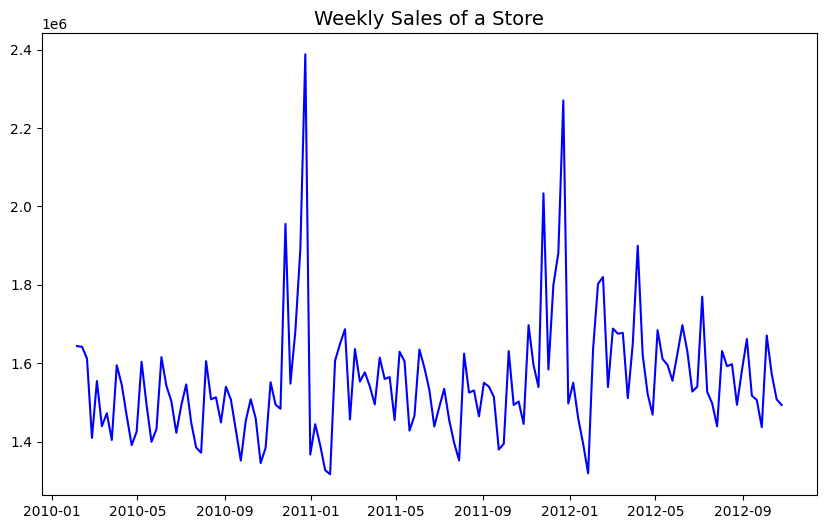

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(sales, color = 'blue')
plt.title('Weekly Sales of a Store', fontsize=14)
plt.show()

### Impact of Unemployment Rate on Weekly Sales

In [ ]:
# Calculate the correlation between Weekly_Sales and Unemployment for each store
correlation_by_store = df.groupby('Store')[['Weekly_Sales', 'Unemployment']].corr().unstack().iloc[:, 1]

# Sort by correlation to find stores most affected (most negative correlation)
most_affected_stores = correlation_by_store.sort_values(ascending=True)

print("Correlation between Weekly Sales and Unemployment Rate for each store:")
display(most_affected_stores.head())

# Get the top 3 most affected stores for visualization
top_affected_store_ids = most_affected_stores.head(3).index.tolist()
print(f"\nStores most affected by unemployment (strongest negative correlation): {top_affected_store_ids}")

Correlation between Weekly Sales and Unemployment Rate for each store:


,Weekly_Sales
,Unemployment
Store,
38,-0.785290
44,-0.780076
39,-0.384681
42,-0.356355
41,-0.350630



Stores most affected by unemployment (strongest negative correlation): [38, 44, 39]


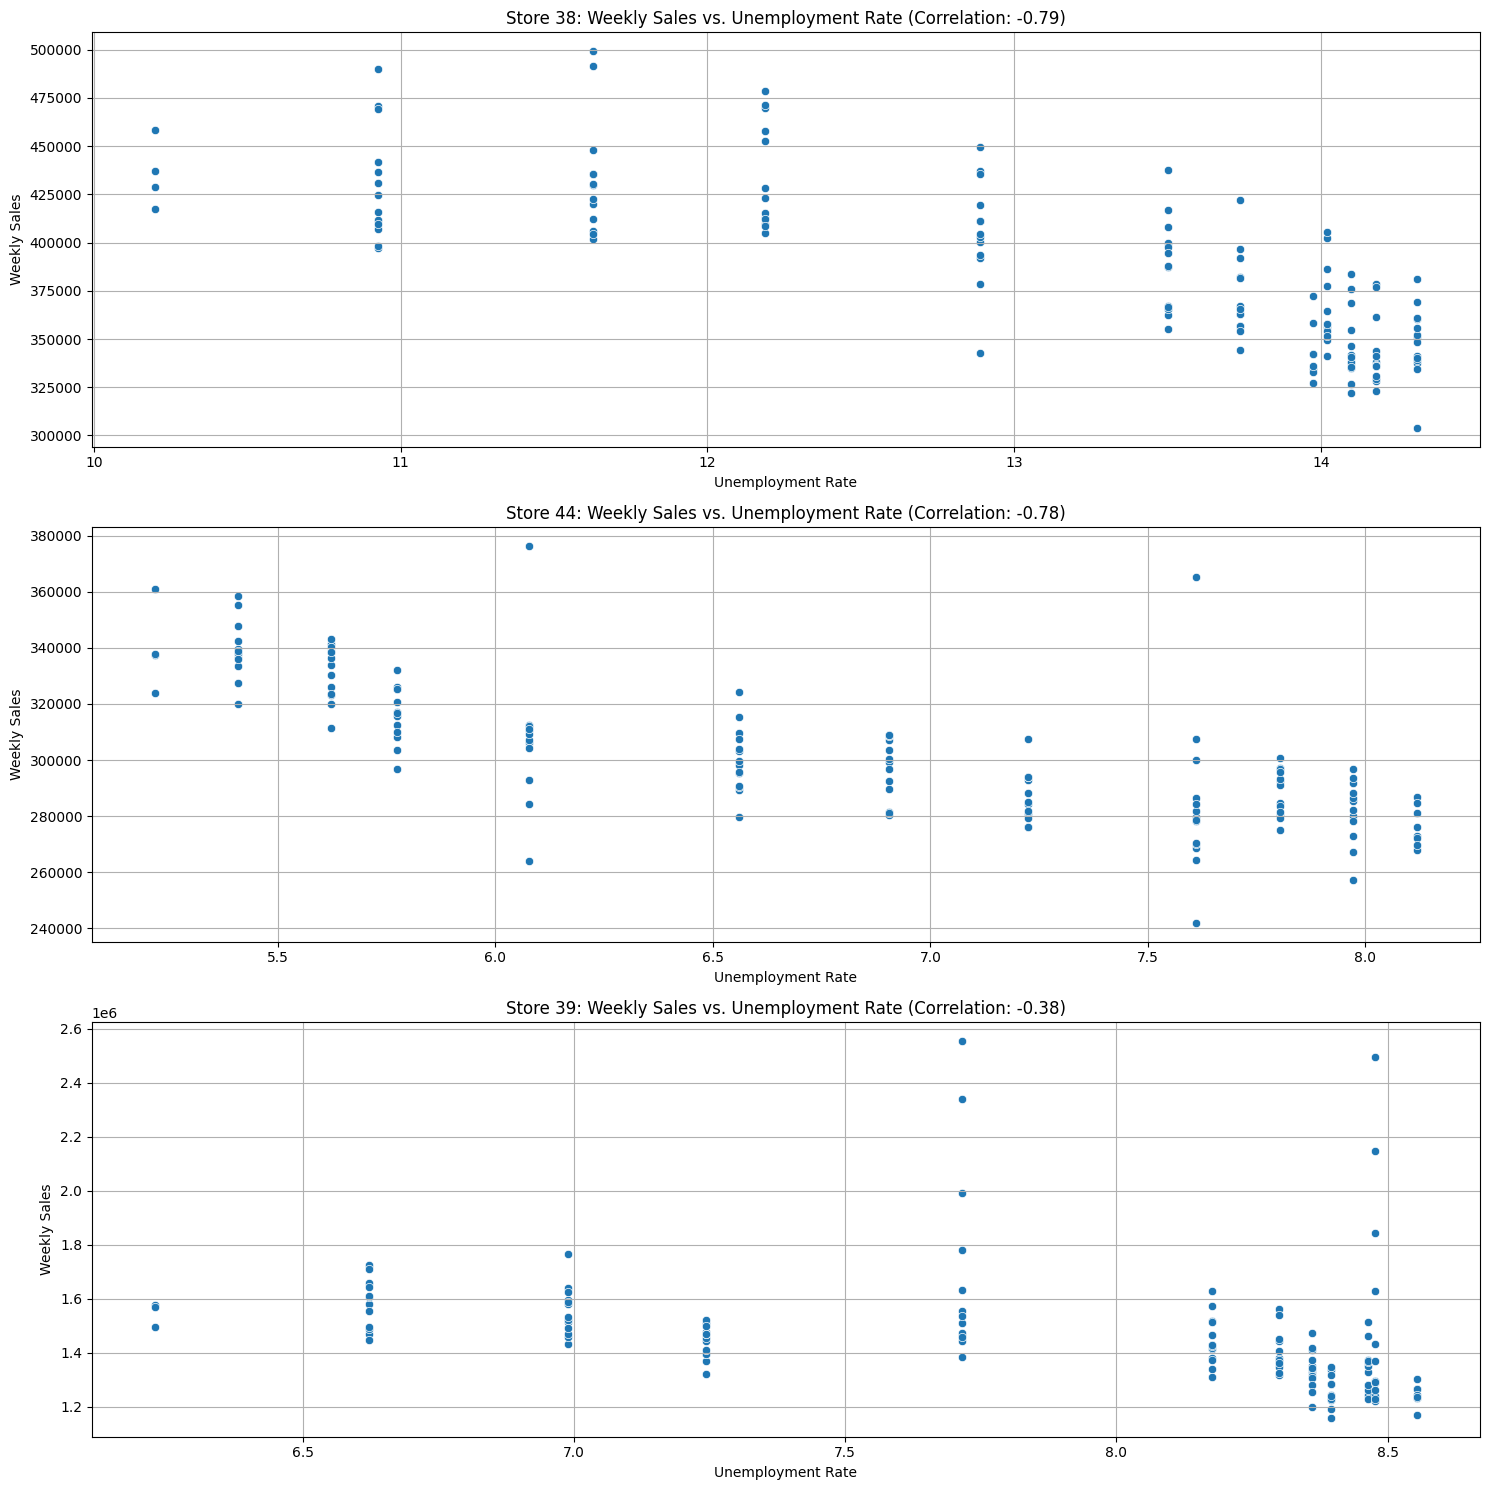

In [ ]:
# Visualize the relationship for the most affected stores

plt.figure(figsize=(15, 5 * len(top_affected_store_ids)))

for i, store_id in enumerate(top_affected_store_ids):
    plt.subplot(len(top_affected_store_ids), 1, i + 1)
    store_data = df[df['Store'] == store_id]
    sns.scatterplot(x='Unemployment', y='Weekly_Sales', data=store_data)
    plt.title(f'Store {store_id}: Weekly Sales vs. Unemployment Rate (Correlation: {correlation_by_store[store_id]:.2f})')
    plt.xlabel('Unemployment Rate')
    plt.ylabel('Weekly Sales')
    plt.grid(True)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

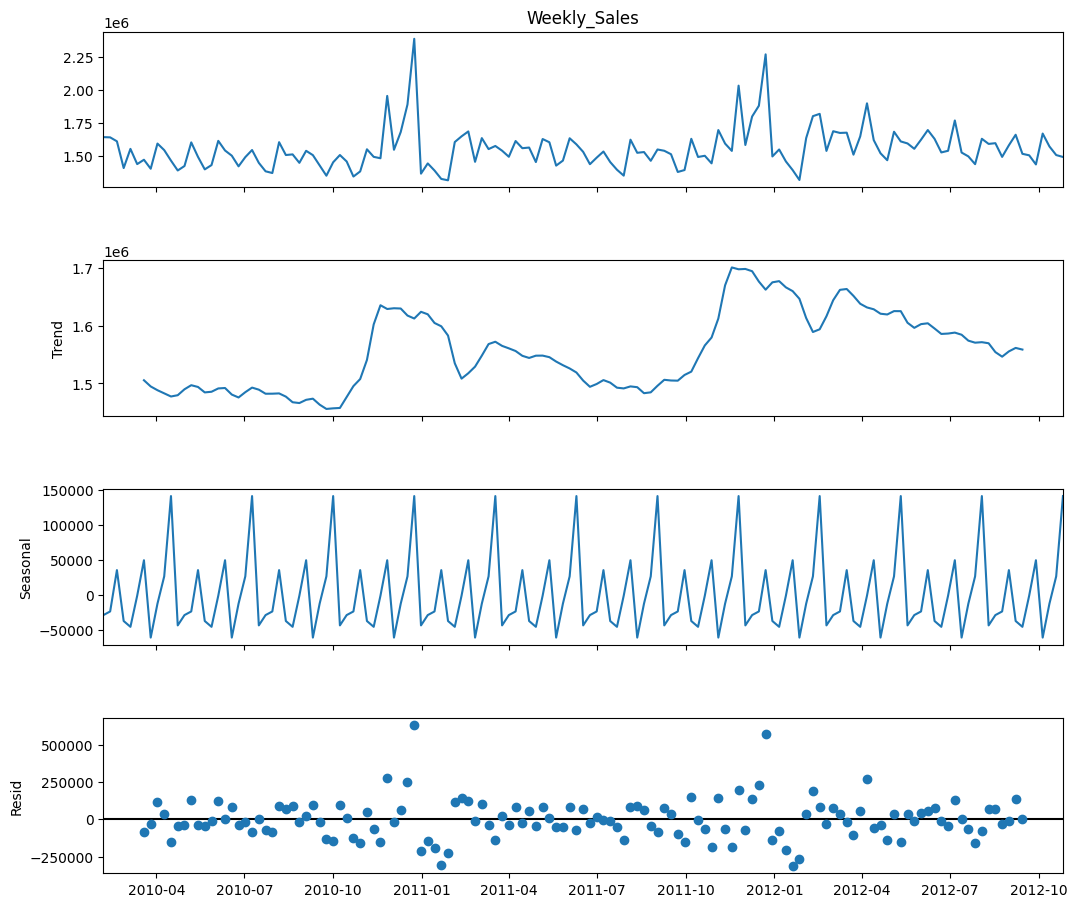

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(sales.Weekly_Sales, period=12)
fig = plt.figure()
fig = decomposition.plot()
fig.set_size_inches(12, 10)
plt.show()

### Impact of Temperature on Weekly Sales

In [ ]:
# Calculate the correlation between Weekly_Sales and Temperature for each store
correlation_temp_by_store = df.groupby('Store')[['Weekly_Sales', 'Temperature']].corr().unstack().iloc[:, 1]

print("Correlation between Weekly Sales and Temperature for each store:")
display(correlation_temp_by_store.head())

# Sort by correlation to find stores most positively and negatively affected by temperature
most_positive_temp_stores = correlation_temp_by_store.sort_values(ascending=False)
most_negative_temp_stores = correlation_temp_by_store.sort_values(ascending=True)

print("\nStores most positively affected by temperature (strongest positive correlation):")
display(most_positive_temp_stores.head(3))

print("\nStores most negatively affected by temperature (strongest negative correlation):")
display(most_negative_temp_stores.head(3))

# Get IDs for visualization: top 1 positive, top 1 negative, and one in the middle (e.g., store 1)
stores_to_visualize = [
    most_positive_temp_stores.index[0],
    most_negative_temp_stores.index[0],
    correlation_temp_by_store.index[0] # Using Store 1 as a general example if not already picked
]

# Remove duplicates and ensure at least 2-3 distinct stores for visualization
stores_to_visualize = list(dict.fromkeys(stores_to_visualize))[:3]

print(f"\nStores selected for visualization: {stores_to_visualize}")

Correlation between Weekly Sales and Temperature for each store:


,Weekly_Sales
,Temperature
Store,
1,-0.222701
2,-0.297673
3,-0.377524
4,-0.225583
5,-0.175517



Stores most positively affected by temperature (strongest positive correlation):


,Weekly_Sales
,Temperature
Store,
44,0.267822
26,0.211722
16,0.182948



Stores most negatively affected by temperature (strongest negative correlation):


,Weekly_Sales
,Temperature
Store,
10,-0.432569
12,-0.379416
3,-0.377524



Stores selected for visualization: [np.int64(44), np.int64(10), np.int64(1)]


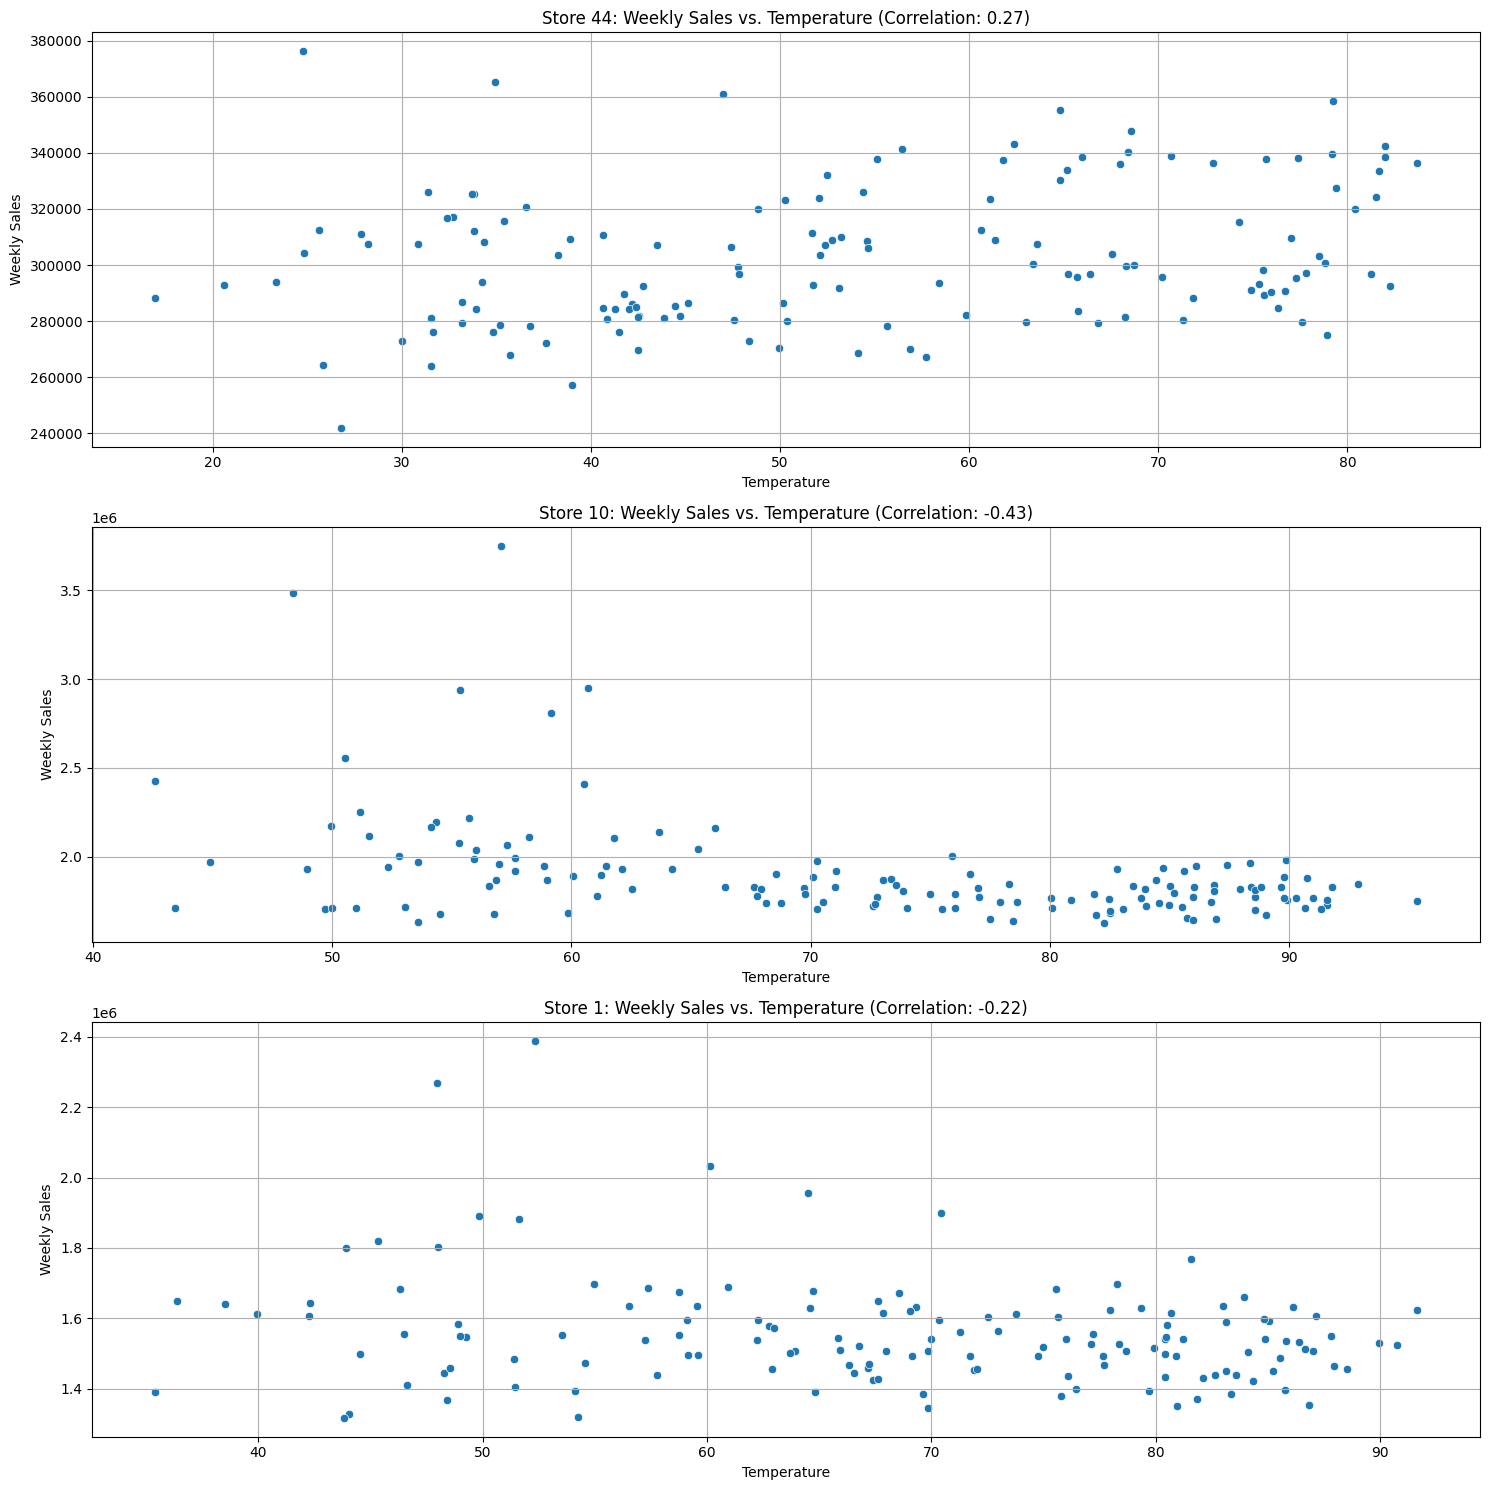

In [ ]:
# Visualize the relationship for the selected stores

plt.figure(figsize=(15, 5 * len(stores_to_visualize)))

for i, store_id in enumerate(stores_to_visualize):
    plt.subplot(len(stores_to_visualize), 1, i + 1)
    store_data = df[df['Store'] == store_id]
    sns.scatterplot(x='Temperature', y='Weekly_Sales', data=store_data)
    correlation_value = correlation_temp_by_store.get(store_id, 'N/A')
    plt.title(f'Store {store_id}: Weekly Sales vs. Temperature (Correlation: {correlation_value:.2f})')
    plt.xlabel('Temperature')
    plt.ylabel('Weekly Sales')
    plt.grid(True)

plt.tight_layout()
plt.show()

**Stores most positively affected by temperature (meaning sales tend to increase with rising temperature):

Store 44: Correlation of 0.27
Store 26: Correlation of 0.21
Store 16: Correlation of 0.18


Stores most negatively affected by temperature (meaning sales tend to decrease with rising temperature):

Store 10: Correlation of -0.43 (This is the strongest negative correlation)
Store 12: Correlation of -0.38
Store 3: Correlation of -0.38**

### Top Performing Stores

In [ ]:
# Calculate total sales for each store
total_sales_by_store = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)

print("Top 5 performing stores based on total weekly sales:")
display(total_sales_by_store.head())

Top 5 performing stores based on total weekly sales:


,Weekly_Sales
Store,
20,3.013978e+08
4,2.995440e+08
14,2.889999e+08
13,2.865177e+08
2,2.753824e+08


### worst performing store

In [ ]:
worst_performing_store = total_sales_by_store.tail(1)
display(worst_performing_store)

highest_sales = total_sales_by_store.max()
lowest_sales = total_sales_by_store.min()
sales_difference = highest_sales - lowest_sales

print(f"\nThe difference in total weekly sales between the highest and lowest performing stores is: ${sales_difference:,.2f}")

,Weekly_Sales
Store,
33,37160221.96



The difference in total weekly sales between the highest and lowest performing stores is: $264,237,570.50


### Forecasting Weekly Sales using SARIMA

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Define the SARIMA model parameters
# Using (p,d,q)(P,D,Q,s) order where s is the seasonal period (12 weeks)
# These parameters can be further optimized, but this is a common starting point.
order = (1, 1, 1)
seasonal_order = (1, 1, 0, 12)

# Fit the SARIMA model
model = SARIMAX(sales['Weekly_Sales'], order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
model_fit = model.fit(disp=False)

print(model_fit.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                        Weekly_Sales   No. Observations:                  143
Model:             SARIMAX(1, 1, 1)x(1, 1, [], 12)   Log Likelihood               -1596.186
Date:                             Sun, 05 Apr 2026   AIC                           3200.372
Time:                                     06:49:20   BIC                           3211.420
Sample:                                 02-05-2010   HQIC                          3204.857
                                      - 10-26-2012                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1849      0.185      0.999      0.318      -0.178       0.548
ma.L1         -0.8047      

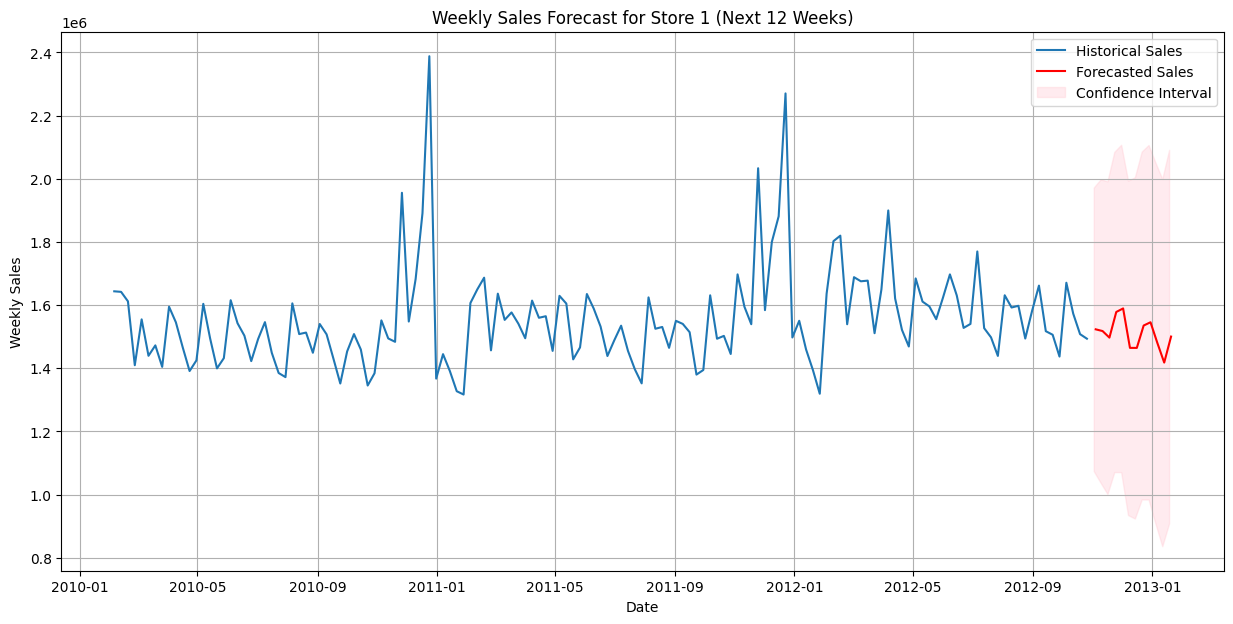

In [ ]:
# Forecast for the next 12 weeks
forecast_steps = 12
forecast = model_fit.get_forecast(steps=forecast_steps)
forecast_ci = forecast.conf_int()

# Create a date index for the forecast (assuming weekly frequency)
last_date = sales.index.max()
forecast_index = pd.date_range(start=last_date, periods=forecast_steps + 1, freq='W')[1:] # +1 and [1:] to get next 12 weeks after last_date
forecast_series = pd.Series(forecast.predicted_mean.values, index=forecast_index)

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(sales['Weekly_Sales'], label='Historical Sales')
plt.plot(forecast_series, label='Forecasted Sales', color='red')
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='pink', alpha=0.3, label='Confidence Interval')
plt.title(f'Weekly Sales Forecast for Store {a} (Next 12 Weeks)')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()